# 정규화 L1 · L2 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week06/regularization/lab/regularization.ipynb)

손실 + λ × 가중치 벌금. 릿지 정답 식을 직접 구현하고, 릿지와 라쏘의 차이를 실제 데이터에서 본다.

- **파트 1**: 릿지 정답 식 직접 구현 → 손 계산 재현 + 기온 9차 곡선 길들이기
- **파트 2**: 진짜 특징 vs 잡음 특징: 계수 경로
- **파트 3**: 당뇨병 환자 442명: 라쏘가 고르는 특징

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
warnings.filterwarnings("ignore")

## 파트 1. 릿지 정답 식

$$\mathbf{w} = (X^\top X + \lambda D)^{-1} X^\top \mathbf{y}, \qquad D = \text{diag}(0, 1, \dots, 1) \ (\text{no penalty on the intercept})$$

슬라이드: $x = 1, 2, 3$, $y = 3, 5, 7$ → λ = 0, 2, 10 에서 (1, 2), (3, 1), (4.33, 0.33).

In [ ]:
def ridge_closed_form(X, y, lam):
    A = np.c_[np.ones(len(X)), X]                         # add intercept column
    D = np.eye(A.shape[1]); D[0, 0] = 0                   # do not penalize the intercept
    return None  # TODO: (A^T A + lam D)^-1 A^T y

x3 = np.array([[1.0], [2.0], [3.0]])
y3 = np.array([3.0, 5.0, 7.0])
for lam in [0, 2, 10]:
    print(f"lambda={lam:2d}: w = {ridge_closed_form(x3, y3, lam).round(2)}")

**예상 결과**

```
lambda= 0: w = [1. 2.]
lambda= 2: w = [3. 1.]
lambda=10: w = [4.33 0.33]
```

In [ ]:
# Temperature example from the slides: 12 measurements, 9th-degree polynomial
hours = np.array([0.1, 0.4, 1.0, 6.5, 13.0, 14.6, 15.3, 17.5, 19.5, 19.6, 21.9, 22.4])
temps = np.array([12.2, 15.2, 14.7, 19.0, 13.0, 11.5, 11.7, 11.3, 10.2, 12.1, 11.6, 13.5])

def true_temp(t):                                         # known only because this is a made-up example
    return 15 + 5 * np.sin(2 * np.pi * t / 24)

def poly_model(reg):
    return make_pipeline(PolynomialFeatures(9, include_bias=False), StandardScaler(), reg)

tt = np.linspace(0, 24, 200)
plt.scatter(hours, temps, color="k", zorder=3); plt.plot(tt, true_temp(tt), "--", color="gray")
for name, reg in [("none", LinearRegression()), ("ridge", Ridge(0.005)), ("lasso", Lasso(0.005, max_iter=500000))]:
    m = poly_model(reg).fit((hours / 24)[:, None], temps)
    pred = m.predict((tt / 24)[:, None])
    error = None  # TODO: RMSE against the true curve
    w = m[-1].coef_
    print(f"{name:6s}: largest |w| {np.abs(w).max():9.1f}   zeros {int((np.abs(w) < 1e-6).sum())}   error vs truth {error:.2f}")
    plt.plot(tt, pred, label=name)
plt.ylim(5, 25); plt.legend(); plt.xlabel("hour"); plt.ylabel("temperature"); plt.show()

**예상 결과**

```
none  : largest |w|   33589.1   zeros 0   error vs truth 3.19
ridge : largest |w|      19.2   zeros 0   error vs truth 1.23
lasso : largest |w|      24.4   zeros 5   error vs truth 1.17
```

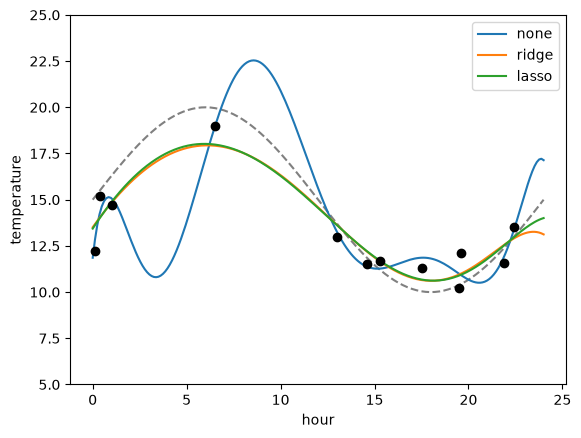

## 파트 2. 계수 경로: 진짜 특징과 잡음 특징

$y = 3x_1 + $ 잡음. $x_2$ 는 y 와 아무 관계없는 잡음 특징. λ 를 키우면 두 가중치가 어떻게 되나?

In [ ]:
rng = np.random.default_rng(0)
x1 = rng.uniform(-1, 1, 30); x2 = rng.normal(0, 1, 30); y = 3 * x1 + rng.normal(0, 1, 30)
X2 = np.c_[x1, x2]
lams = np.logspace(-2, np.log10(2.5), 60)
ridge_w = np.array([Ridge(alpha=30 * l).fit(X2, y).coef_ for l in lams])
lasso_w = None  # TODO: lasso coefficients for each lambda
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, W, t in [(axs[0], ridge_w, "ridge"), (axs[1], lasso_w, "lasso")]:
    ax.plot(lams, W[:, 0], label="x1 (real)"); ax.plot(lams, W[:, 1], label="x2 (noise)")
    ax.set_xscale("log"); ax.axhline(0, color="k", lw=0.8); ax.set_title(t); ax.set_xlabel("lambda")
axs[0].legend(); plt.show()
print("first lambda where lasso sets x2 to 0:", lams[np.argmax(np.abs(lasso_w[:, 1]) < 1e-9)].round(3))

**예상 결과**

```
first lambda where lasso sets x2 to 0: 0.137
```

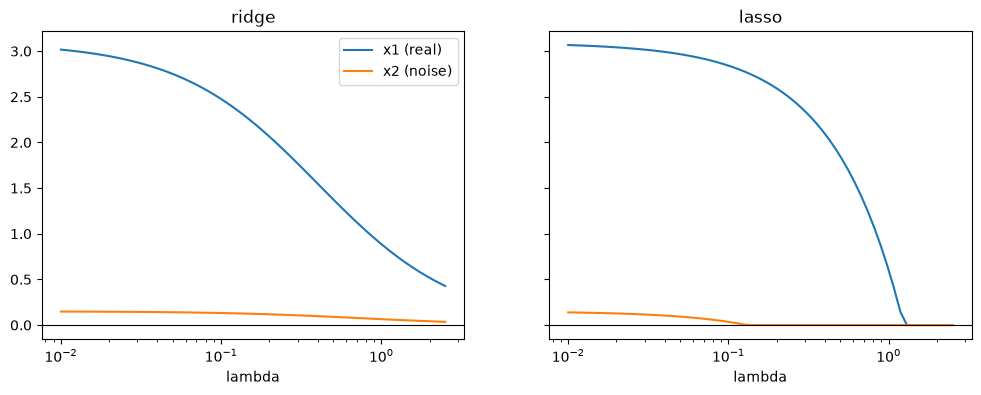

## 파트 3. 실제 데이터: 당뇨병 진행 예측

환자 442명의 나이, 성별, BMI, 혈압, 혈액 검사 6가지 (s1~s6) → 1년 뒤 병의 진행 정도. 특징은 이미 표준화돼 있다. λ 를 줄여 가며 라쏘가 어떤 특징부터 살리는지 보자.

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import cross_val_score
data = load_diabetes()
Xd, yd, names = data.data, data.target, data.feature_names
print(Xd.shape, names)

lams = np.logspace(1, -2, 40)
paths = np.array([Lasso(alpha=l, max_iter=100000).fit(Xd, yd).coef_ for l in lams])
for j, n in enumerate(names):
    alive = np.abs(paths[:, j]) > 1e-9
    first = lams[np.argmax(alive)] if alive.any() else None
    print(f"{n:4s}: becomes nonzero at lambda = {first if first is None else round(first, 3)}")
plt.plot(lams, paths); plt.xscale("log"); plt.gca().invert_xaxis(); plt.xlabel("lambda (decreasing)"); plt.ylabel("coefficient"); plt.legend(names, fontsize=7); plt.show()

**예상 결과**

```
(442, 10) ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
age : becomes nonzero at lambda = 0.01
sex : becomes nonzero at lambda = 0.289
bmi : becomes nonzero at lambda = 2.031
bp  : becomes nonzero at lambda = 1.0
s1  : becomes nonzero at lambda = 0.143
s2  : becomes nonzero at lambda = 0.012
s3  : becomes nonzero at lambda = 0.702
s4  : becomes nonzero at lambda = 0.041
s5  : becomes nonzero at lambda = 1.701
s6  : becomes nonzero at lambda = 0.17
```

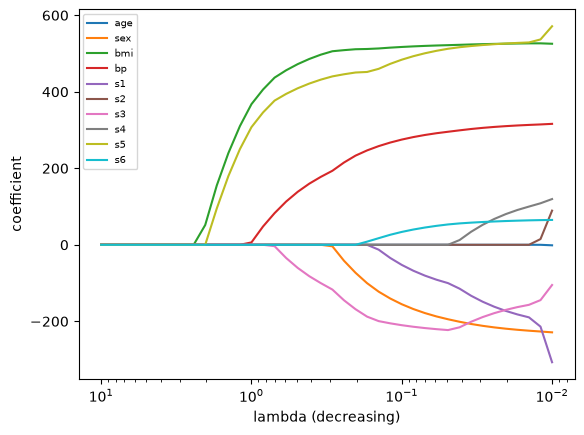

In [ ]:
# Does regularization help on unseen data? Compare 5-fold CV error (lower is better)
for name, reg in [("plain", LinearRegression()), ("lasso 0.001", Lasso(0.001, max_iter=100000)), ("lasso 0.05", Lasso(0.05, max_iter=100000)),
                  ("lasso 0.5", Lasso(0.5, max_iter=100000)), ("lasso 2", Lasso(2, max_iter=100000))]:
    mse = -cross_val_score(reg, Xd, yd, cv=5, scoring="neg_mean_squared_error").mean()
    n_used = int((np.abs(reg.fit(Xd, yd).coef_) > 1e-9).sum())
    print(f"{name:11s}: CV RMSE {np.sqrt(mse):6.2f}   features used {n_used}")

**예상 결과**

```
plain      : CV RMSE  54.71   features used 10
lasso 0.001: CV RMSE  54.71   features used 10
lasso 0.05 : CV RMSE  54.72   features used 7
lasso 0.5  : CV RMSE  57.21   features used 4
lasso 2    : CV RMSE  75.77   features used 2
```

**확인 질문**
1. 파트 1 에서 λ 를 1000 으로 하면 (w0, w1) 은? 왜 그런가?
2. 파트 1 의 기온 예에서 Ridge 의 λ 를 1e-6, 1e-3, 100 으로 바꿔 보자. 슬라이드의 U 자 (1.59, 0.99, 3.78) 를 재현하나?
3. 파트 3 에서 라쏘가 가장 먼저 살리는 두 특징은? 의학적으로 그럴듯한가?
4. 파트 3 의 마지막 칸: λ 가 너무 크면 오차가 크게 늘고, 0.05 에서는 특징을 7개만 쓰고도 오차가 거의 같다. λ 를 정직하게 고르려면 어떻게 해야 할까? (다음 시간: 교차 검증)

데이터 출처: Efron, Hastie, Johnstone, Tibshirani (2004) Least Angle Regression, Annals of Statistics 32(2) · scikit-learn `load_diabetes`.